# Week 10 Lab: Recommendation Systems (Content-Based and Collaborative Filtering)
**CSE303 Machine Learning | Unit: Recommender Systems | Syllabus: content-based filtering, collaborative filtering**

Pattern: **demo → practice → predict-then-run → deliberate error → reflection**, then an end-to-end **mini project** of your choice (handout: `Week10_Recsys_Project_Menu.docx`).

| Part | Topic | Track |
|---|---|---|
| 1 | The user × item rating matrix and sparsity | core |
| 2 | Content-based filtering (TF-IDF, cosine, user profile) | core |
| 3 | Collaborative filtering (user-based, item-based, mean-centering) | core |
| 4 | Evaluating a recommender (RMSE, precision@k, baselines, leakage) | core |
| 5 | Cold start and a simple hybrid | core |
| 6 | Mini project (end-to-end pipeline) | project |
| 7 | Reflection and capstone link | |

**Rule carried from Weeks 5 and 9:** split first. Anything learned from data (means, similarities, TF-IDF vocabulary) must be computed on **train only**.

**Why this week matters:** Netflix, YouTube, Amazon, Spotify, Swiggy and LinkedIn all run on recommenders. The two ideas you learn here (similar *items* by content, similar *users* by behaviour) are the foundation of every production system, including the deep-learning ones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.precision', 3)
np.random.seed(1)


## Part 1: The Rating Matrix and Sparsity
A recommender starts from a table with one row per user and one column per item. Most cells are **empty** because nobody has watched everything. Predicting the empty cells is the whole problem.

Below: 12 films (each with a short text description) and 8 users who have rated a few of them (1 to 5).

In [2]:
movies = pd.DataFrame({
 'title':['Cricket Fever','Match Point','Spice Route','Curry Nights','Chip Wars','Quantum Phone',
          'Last Over','Pasta Masters','Robot Uprising','Boundary Line','Street Food Tales','Silicon Dreams'],
 'desc':['cricket team underdog sports tournament victory',
         'tennis rivalry sports championship coach athlete',
         'cooking travel spices chef kitchen street',
         'chef curry kitchen family restaurant cooking',
         'technology startup processor chips rivalry gadgets',
         'technology phone quantum science gadgets future',
         'cricket sports final over pressure team',
         'cooking pasta chef competition kitchen',
         'technology robot science future artificial',
         'cricket sports batsman boundary stadium',
         'cooking street food travel chef stories',
         'technology startup silicon gadgets future']})

users = ['Asha','Bala','Chitra','Dev','Esha','Farid','Gita','Hari']
data = {
 'Asha':  {'Cricket Fever':5,'Match Point':4,'Last Over':5,'Spice Route':1,'Chip Wars':2},
 'Bala':  {'Cricket Fever':5,'Boundary Line':4,'Match Point':5,'Pasta Masters':2,'Quantum Phone':1},
 'Chitra':{'Spice Route':5,'Curry Nights':5,'Pasta Masters':4,'Cricket Fever':1,'Robot Uprising':2},
 'Dev':   {'Curry Nights':4,'Street Food Tales':5,'Spice Route':4,'Last Over':2},
 'Esha':  {'Quantum Phone':5,'Chip Wars':4,'Robot Uprising':5,'Silicon Dreams':5,'Pasta Masters':1},
 'Farid': {'Chip Wars':5,'Silicon Dreams':4,'Quantum Phone':4,'Match Point':2},
 'Gita':  {'Cricket Fever':4,'Curry Nights':4,'Quantum Phone':4,'Street Food Tales':3,'Robot Uprising':3},
 'Hari':  {'Boundary Line':5,'Last Over':4,'Cricket Fever':5,'Spice Route':2,'Silicon Dreams':1},
}
R = pd.DataFrame(np.nan, index=users, columns=movies.title)
for u, d in data.items():
    for m, v in d.items():
        R.loc[u, m] = v
R


title,Cricket Fever,Match Point,Spice Route,Curry Nights,Chip Wars,Quantum Phone,Last Over,Pasta Masters,Robot Uprising,Boundary Line,Street Food Tales,Silicon Dreams
Asha,5.0,4.0,1.0,NaN,2.0,NaN,5.0,NaN,NaN,NaN,NaN,NaN
Bala,5.0,5.0,NaN,NaN,NaN,1.0,NaN,2.0,NaN,4.0,NaN,NaN
Chitra,1.0,NaN,5.0,5.0,NaN,NaN,NaN,4.0,2.0,NaN,NaN,NaN
Dev,NaN,NaN,4.0,4.0,NaN,NaN,2.0,NaN,NaN,NaN,5.0,NaN
Esha,NaN,NaN,NaN,NaN,4.0,5.0,NaN,1.0,5.0,NaN,NaN,5.0
Farid,NaN,2.0,NaN,NaN,5.0,4.0,NaN,NaN,NaN,NaN,NaN,4.0
Gita,4.0,NaN,NaN,4.0,NaN,4.0,NaN,NaN,3.0,NaN,3.0,NaN
Hari,5.0,NaN,2.0,NaN,NaN,NaN,4.0,NaN,NaN,5.0,NaN,1.0


In [3]:
n_ratings = int(R.notna().sum().sum())
print('ratings:', n_ratings, 'of', R.size, 'cells')
print('sparsity (share of empty cells):', round(1 - n_ratings / R.size, 3))


ratings: 38 of 96 cells
sparsity (share of empty cells): 0.604


**Predict, then think:** Netflix-scale data has millions of users and tens of thousands of titles. Would you expect the sparsity there to be *lower* or *higher* than here (60%)? What does that mean for methods that need two users to have rated the *same* items?

*Your answer:*Sparsity would be much higher than 60% because each user watches or rates only a small fraction of the available movies.

This makes collaborative filtering more difficult because two users may have rated very few common movies. As a result, calculating similarities between users becomes less reliable.

### Student Practice 1
1. How many ratings does each user have? Each movie?
2. Which movie has the most ratings (the most *popular*)? Which has the highest *average* rating? Are they the same movie?
3. Why is "most popular" a poor recommendation for every user, even though it is easy to compute?

In [4]:
# Write your answer here
print("Ratings per user:")
print(R.notna().sum(axis=1))

print("\nRatings per movie:")
print(R.notna().sum(axis=0))

print("\nMost popular movie:")
print(R.notna().sum().idxmax())

print("\nAverage rating per movie:")
print(R.mean().sort_values(ascending=False))

print("\nMovie with highest average rating:")
print(R.mean().idxmax())

n_ratings = int(R.notna().sum().sum())
print("\nTotal ratings:", n_ratings)
print("Sparsity:", round(1 - n_ratings / R.size, 3))

Ratings per user:
Asha      5
Bala      5
Chitra    5
Dev       4
Esha      5
Farid     4
Gita      5
Hari      5
dtype: int64

Ratings per movie:
title
Cricket Fever        5
Match Point          3
Spice Route          4
Curry Nights         3
Chip Wars            3
Quantum Phone        4
Last Over            3
Pasta Masters        3
Robot Uprising       3
Boundary Line        2
Street Food Tales    2
Silicon Dreams       3
dtype: int64

Most popular movie:
Cricket Fever

Average rating per movie:
title
Boundary Line        4.500
Curry Nights         4.333
Street Food Tales    4.000
Cricket Fever        4.000
Chip Wars            3.667
Match Point          3.667
Last Over            3.667
Quantum Phone        3.500
Silicon Dreams       3.333
Robot Uprising       3.333
Spice Route          3.000
Pasta Masters        2.333
dtype: float64

Movie with highest average rating:
Boundary Line

Total ratings: 38
Sparsity: 0.604


## Part 2: Content-Based Filtering
Idea: describe every **item** by its content, describe every **user** by the content of what they liked, and recommend items whose content matches the user's profile. Needs no other users.

Step 1: turn each description into a **TF-IDF** vector (words that appear in few items count more). Step 2: **cosine similarity** between items.

In [5]:
tfidf = TfidfVectorizer()
T = tfidf.fit_transform(movies.desc)           # items x words (sparse)
S_item = cosine_similarity(T)                   # items x items
titles = list(movies.title)

i = titles.index('Cricket Fever')
print(pd.Series(S_item[i], index=titles).sort_values(ascending=False).head(4))


Cricket Fever    1.000
Last Over        0.372
Boundary Line    0.237
Match Point      0.093
dtype: float64


**Predict, then think:** `Chip Wars` is a technology film about rivalry, and `Match Point` is a sports film about rivalry. Will they be more similar to each other than `Chip Wars` is to `Silicon Dreams`? Write your guess, then check it in the practice cell.

No. Chip Wars is more similar to Silicon Dreams because both are technology movies and share more important words in their descriptions.

Although Chip Wars and Match Point both contain the idea of rivalry, their descriptions belong to different topics.

### Student Practice 2
1. Print the similarity between `Chip Wars` and `Match Point`, and between `Chip Wars` and `Silicon Dreams`. Was your guess right?
2. Which 3 films are most similar to `Spice Route`?

In [6]:
# Write your answer here
def get_similarity(movie1, movie2):
    i = titles.index(movie1)
    j = titles.index(movie2)
    return S_item[i, j]

print("Chip Wars - Match Point:",
      round(get_similarity("Chip Wars", "Match Point"), 3))

print("Chip Wars - Silicon Dreams:",
      round(get_similarity("Chip Wars", "Silicon Dreams"), 3))

i = titles.index("Spice Route")

print("\nTop 3 movies similar to Spice Route:")
print(
    pd.Series(S_item[i], index=titles)
    .drop("Spice Route")
    .sort_values(ascending=False)
    .head(3)
)

Chip Wars - Match Point: 0.152
Chip Wars - Silicon Dreams: 0.457

Top 3 movies similar to Spice Route:
Street Food Tales    0.574
Pasta Masters        0.403
Curry Nights         0.355
dtype: float64


### Building a user profile
A user profile is a weighted sum of the vectors of the items they rated. We weight by **rating minus the user's own average**, so a 1-star film pushes the profile *away* from its content and a 5-star film pulls it *toward* it. Then we score unseen items by cosine similarity to the profile.

In [7]:
def user_profile(u):
    r = R.loc[u].dropna()
    w = r - r.mean()                                   # mean-centred weights
    idx = [titles.index(m) for m in r.index]
    return np.asarray(T[idx].T.dot(w.values)).ravel()

def recommend_cb(u, n=3):
    p = user_profile(u)
    scores = pd.Series(cosine_similarity(p.reshape(1, -1), T).ravel(), index=titles)
    return scores[R.loc[u].isna()].sort_values(ascending=False).head(n)   # unseen only

print('Asha:\n', recommend_cb('Asha'))


Asha:
 Boundary Line     0.210
Robot Uprising   -0.040
Quantum Phone    -0.084
dtype: float64


### Student Practice 3
1. Recommend 3 films for `Gita` (she likes sports, cooking and tech). Do the scores look confident? Why or why not?
2. Which of Asha's ratings pulls her profile *away* from cooking content? (Look at the weights `r - r.mean()`.)

In [8]:
# Write your answer here
print("Recommendations for Gita:")
print(recommend_cb("Gita", 3))

r = R.loc["Asha"].dropna()
weights = r - r.mean()

print("\nAsha's mean-centred ratings:")
print(weights)

print("\nRatings with negative weights:")
print(weights[weights < 0])

Recommendations for Gita:
Last Over        0.158
Boundary Line    0.100
Match Point      0.039
dtype: float64

Asha's mean-centred ratings:
title
Cricket Fever    1.6
Match Point      0.6
Spice Route     -2.4
Chip Wars       -1.4
Last Over        1.6
Name: Asha, dtype: float64

Ratings with negative weights:
title
Spice Route   -2.4
Chip Wars     -1.4
Name: Asha, dtype: float64


### Deliberate error 1: forgetting to mean-centre
Run the cell, then answer: why does this version recommend things Asha would dislike?

In [9]:
def recommend_cb_raw(u, n=3):
    r = R.loc[u].dropna()                              # WRONG: raw ratings as weights
    idx = [titles.index(m) for m in r.index]
    p = np.asarray(T[idx].T.dot(r.values)).ravel()
    s = pd.Series(cosine_similarity(p.reshape(1, -1), T).ravel(), index=titles)
    return s[R.loc[u].isna()].sort_values(ascending=False).head(n)

print('Asha, WRONG (raw weights):\n', recommend_cb_raw('Asha'))
print('Asha, correct (centred)  :\n', recommend_cb('Asha'))


Asha, WRONG (raw weights):
 Boundary Line        0.278
Silicon Dreams       0.092
Street Food Tales    0.058
dtype: float64
Asha, correct (centred)  :
 Boundary Line     0.210
Robot Uprising   -0.040
Quantum Phone    -0.084
dtype: float64


*Your answer (one line):*

The incorrect version uses raw ratings as weights, so even movies Asha rated poorly contribute positively to her profile, whereas mean-centring assigns negative weights to movies she dislikes.



## Part 3: Collaborative Filtering
Idea: **ignore content entirely**. Find users who rate like you and recommend what they liked. Works for any item type (a song, a job, a drug), but needs overlapping ratings.

Key steps for **user-based** CF:
1. Mean-centre each user's ratings (a harsh rater's 4 equals a generous rater's 5).
2. Compute user-user similarity on the centred matrix.
3. Predict: $\hat r_{u,m}=\bar r_u+\dfrac{\sum_{v} sim(u,v)\,(r_{v,m}-\bar r_v)}{\sum_{v}|sim(u,v)|}$ over the top-k similar users who rated $m$.

In [10]:
def build_user_cf(R_train):
    means = R_train.mean(axis=1)
    C = R_train.sub(means, axis=0).fillna(0)            # centred; unrated -> 0 = "no opinion"
    sim = pd.DataFrame(cosine_similarity(C), index=R_train.index, columns=R_train.index)
    return means, sim

def predict_user_cf(R_train, means, sim, u, m, k=3):
    raters = R_train[m].dropna().index.difference([u])
    if len(raters) == 0:
        return means[u]                                  # nobody rated it: fall back to user mean
    s = sim.loc[u, raters].sort_values(ascending=False).head(k)
    s = s[s > 0]
    if len(s) == 0:
        return means[u]
    return means[u] + (s * (R_train.loc[s.index, m] - means[s.index])).sum() / s.abs().sum()

means, sim_u = build_user_cf(R)
print(sim_u.round(2))
print()
print('Asha  -> Boundary Line :', round(predict_user_cf(R, means, sim_u, 'Asha', 'Boundary Line'), 2))
print('Gita  -> Pasta Masters :', round(predict_user_cf(R, means, sim_u, 'Gita', 'Pasta Masters'), 2))


        Asha  Bala  Chitra   Dev  Esha  Farid  Gita  Hari
Asha    1.00  0.27   -0.58 -0.43  0.00  -0.35  0.16  0.52
Bala    0.27  1.00   -0.35  0.00  0.14  -0.43 -0.08  0.27
Chitra -0.58 -0.35    1.00  0.10 -0.25   0.00  0.13 -0.46
Dev    -0.43  0.00    0.10  1.00  0.00   0.00 -0.27 -0.18
Esha    0.00  0.14   -0.25  0.00  1.00   0.07 -0.05 -0.19
Farid  -0.35 -0.43    0.00  0.00  0.07   1.00  0.04 -0.08
Gita    0.16 -0.08    0.13 -0.27 -0.05   0.04  1.00  0.16
Hari    0.52  0.27   -0.46 -0.18 -0.19  -0.08  0.16  1.00

Asha  -> Boundary Line : 4.66
Gita  -> Pasta Masters : 4.2


**Predict, then think:** Asha and Hari both love cricket films. Their similarity above should be the largest positive value in Asha's row. Is it? And what sign do you expect between Asha and Chitra (cooking fan who disliked `Cricket Fever`)?

Yes, Asha and Hari should have the largest positive similarity because both enjoy cricket films, while Asha and Chitra should have a **negative similarity** because their movie preferences are different.

### Student Practice 4
1. List the 3 most similar users to `Asha` and the 3 *least* similar. Do they match your intuition?
2. Predict `Esha -> Match Point` and `Dev -> Cricket Fever`. For each, which users were used?
3. **Item-based CF:** build item-item similarity from the *centred* matrix (centre by user, then take cosine between *columns*) and predict `Asha -> Boundary Line` as the similarity-weighted average of Asha's own ratings on the most similar rated items. Compare with the user-based answer.

In [11]:
# Write your answer here
print("Three most similar users to Asha:")
print(
    sim_u.loc["Asha"]
    .drop("Asha")
    .sort_values(ascending=False)
    .head(3)
)

print("\nThree least similar users to Asha:")
print(
    sim_u.loc["Asha"]
    .drop("Asha")
    .sort_values()
    .head(3)
)

print("\nEsha -> Match Point:",
      round(predict_user_cf(R, means, sim_u, "Esha", "Match Point"), 2))

print("Dev -> Cricket Fever:",
      round(predict_user_cf(R, means, sim_u, "Dev", "Cricket Fever"), 2))

C = R.sub(R.mean(axis=1), axis=0).fillna(0)

sim_item = pd.DataFrame(
    cosine_similarity(C.T),
    index=R.columns,
    columns=R.columns
)

def predict_item_cf(R_train, sim, u, m, k=3):
    rated = R_train.loc[u].dropna().index

    s = sim.loc[m, rated].sort_values(ascending=False).head(k)
    s = s[s > 0]

    mean_u = R_train.loc[u].mean()

    if len(s) == 0:
        return mean_u

    return mean_u + (
        s * (R_train.loc[u, s.index] - mean_u)
    ).sum() / s.abs().sum()

print("\nAsha -> Boundary Line (item-based):",
      round(predict_item_cf(R, sim_item, "Asha", "Boundary Line"), 2))

print("Asha -> Boundary Line (user-based):",
      round(predict_user_cf(R, means, sim_u, "Asha", "Boundary Line"), 2))

Three most similar users to Asha:
Hari    0.521
Bala    0.267
Gita    0.161
Name: Asha, dtype: float64

Three least similar users to Asha:
Chitra   -0.582
Dev      -0.429
Farid    -0.354
Name: Asha, dtype: float64

Esha -> Match Point: 4.54
Dev -> Cricket Fever: 1.35

Asha -> Boundary Line (item-based): 4.77
Asha -> Boundary Line (user-based): 4.66


### Deliberate error 2: treating "unrated" as "rated 0"
Run the cell. Compare the two similarity rows for Asha. Why is filling gaps with 0 on the *raw* matrix wrong?

In [12]:
sim_raw0 = pd.DataFrame(cosine_similarity(R.fillna(0)), index=users, columns=users)   # WRONG
print('raw, gaps=0 :', sim_raw0.loc['Asha'].drop('Asha').round(2).to_dict())
print('centred     :', sim_u.loc['Asha'].drop('Asha').round(2).to_dict())


raw, gaps=0 : {'Bala': 0.63, 'Chitra': 0.14, 'Dev': 0.21, 'Esha': 0.1, 'Farid': 0.27, 'Gita': 0.29, 'Hari': 0.66}
centred     : {'Bala': 0.27, 'Chitra': -0.58, 'Dev': -0.43, 'Esha': 0.0, 'Farid': -0.35, 'Gita': 0.16, 'Hari': 0.52}


*Your answer (one or two lines):* An unrated movie does not mean that the user dislikes it. Filling missing ratings with zero incorrectly treats the absence of a rating as an actual rating of zero.

This distorts similarities between users. Mean-centring the ratings and then filling missing centred values with zero is better because zero then represents no positive or negative deviation from the user's average.

## Part 4: Evaluating a Recommender
You cannot judge a recommender on ratings it has already seen. **Hold out some known ratings, hide them, predict them, compare.**

- **RMSE** for rating prediction: $\sqrt{\frac1n\sum(\hat r-r)^2}$. Lower is better.
- Always compare with **baselines**: the global mean, and each user's own mean. A model that cannot beat these is not learning anything useful.

Our toy matrix has only 38 ratings, too few to evaluate honestly. So we switch to a **generated** dataset with the same structure: 60 users, 30 films in three genres, about 35% of cells observed, and each user having a favourite genre. (In your project you will use real data.)

In [13]:
def make_data(n_users=60, n_items=30, density=0.35, seed=1):
    rng = np.random.RandomState(seed)
    vocab = {'sports':  ['cricket','match','team','stadium','batsman','tennis','coach','tournament'],
             'cooking': ['chef','kitchen','curry','pasta','spices','restaurant','recipe','street'],
             'tech':    ['phone','processor','startup','gadgets','robot','battery','laptop','science']}
    genres, common = list(vocab), ['new','story','family','final','night','world']
    names = [f'Film{i:02d}' for i in range(n_items)]
    g_item = [genres[i % 3] for i in range(n_items)]
    desc = [' '.join(list(rng.choice(vocab[g], 3, replace=False)) + list(rng.choice(common, 1))) for g in g_item]
    ub, ib = rng.normal(0, 0.3, n_users), rng.normal(0, 0.2, n_items)
    fav = rng.randint(0, 3, n_users)
    Rb = pd.DataFrame(np.nan, index=[f'U{u:02d}' for u in range(n_users)], columns=names)
    for u in range(n_users):
        for i in range(n_items):
            if rng.rand() < density:
                aff = 1.6 if genres.index(g_item[i]) == fav[u] else -1.0
                r = 3 + aff + ub[u] + ib[i] + rng.normal(0, 0.5)
                Rb.iloc[u, i] = float(np.clip(np.round(r), 1, 5))
    return Rb, pd.DataFrame({'title': names, 'desc': desc, 'genre': g_item})

Rb, items = make_data()
print('ratings:', int(Rb.notna().sum().sum()), '| sparsity:', round(1 - Rb.notna().sum().sum() / Rb.size, 3))
print('fewest ratings by one user:', int(Rb.notna().sum(axis=1).min()))
items.head(4)


ratings: 609 | sparsity: 0.662
fewest ratings by one user: 4


,title,desc,genre
0,Film00,tournament team match world,sports
1,Film01,curry pasta spices story,cooking
2,Film02,processor laptop gadgets night,tech
3,Film03,cricket tournament match new,sports


In [14]:
# Content similarity for the generated films, as a labelled table (rows/cols = film names)
tfidf_b = TfidfVectorizer().fit(items.desc)
Tb = tfidf_b.transform(items.desc)
S_b = pd.DataFrame(cosine_similarity(Tb), index=items.title, columns=items.title)

def predict_cb(R_train, S, u, m, k=3):
    """Content-based rating prediction: user's mean + similarity-weighted centred ratings of content-similar rated items."""
    rated = R_train.loc[u].dropna().index.difference([m])
    sims = S.loc[m, rated].sort_values(ascending=False).head(k)
    sims = sims[sims > 0]
    mu = R_train.loc[u].mean()
    if len(sims) == 0:
        return mu
    return mu + (sims * (R_train.loc[u, sims.index] - mu)).sum() / sims.abs().sum()

def rmse(pred, true):
    pred, true = np.array(pred), np.array(true)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

# hold out 20% of the known ratings (split the RATINGS, not the users)
rng = np.random.RandomState(1)
pairs = [(u, m) for u in Rb.index for m in Rb.columns if not np.isnan(Rb.loc[u, m])]
test_pairs = [pairs[i] for i in rng.choice(len(pairs), size=int(0.2 * len(pairs)), replace=False)]
Rb_train = Rb.copy()
for u, m in test_pairs:
    Rb_train.loc[u, m] = np.nan                                   # hide the test ratings
true = [Rb.loc[u, m] for u, m in test_pairs]
print('train ratings:', int(Rb_train.notna().sum().sum()), '| test ratings:', len(test_pairs))

means_tr, sim_tr = build_user_cf(Rb_train)                        # fitted on TRAIN only
gmean = np.nanmean(Rb_train.values)

p_global = [gmean for _ in test_pairs]
p_user   = [means_tr[u] for u, m in test_pairs]
p_cf     = [predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=5) for u, m in test_pairs]

print('RMSE global mean :', round(rmse(p_global, true), 3))
print('RMSE user mean   :', round(rmse(p_user, true), 3))
print('RMSE user-CF k=5 :', round(rmse(p_cf, true), 3))


train ratings: 488 | test ratings: 121
RMSE global mean : 1.354
RMSE user mean   : 1.499
RMSE user-CF k=5 : 1.169


**Predict, then think:** the user-mean baseline can be *worse* than the global mean. Why might that happen when each user has only about 10 ratings, and the user's ratings come mostly from their favourite or least-favourite genre?

*Your answer:*

The user-mean baseline can be worse because 10 ratings may mostly come from the user's favourite or least-favourite genre, making their average rating unrepresentative of their overall preferences, while the global mean uses ratings from all users.

### Student Practice 5
1. Add **item-based CF** (reuse `predict_item_cf`, with an item-item similarity built from `Rb_train` only) and **content-based** (`predict_cb` with `S_b`). Report RMSE for all five methods in one table.
2. Try `k` in [1, 3, 5, 10, 20] for user-CF. Plot RMSE against k. Which k would you pick? What happens at k=1?
3. **Precision@3:** for each user with at least one held-out rating of 4 or more, recommend the top 3 unseen items by user-CF prediction (using `Rb_train`); count how many of that user's held-out high ratings appear in the top 3. Report the mean over those users.

In [15]:
# Write your answer here
C_train = Rb_train.sub(
    Rb_train.mean(axis=1), axis=0
).fillna(0)

S_item_train = pd.DataFrame(
    cosine_similarity(C_train.T),
    index=Rb_train.columns,
    columns=Rb_train.columns
)

p_item = [
    predict_item_cf(Rb_train, S_item_train, u, m, k=5)
    for u, m in test_pairs
]

p_cb = [
    predict_cb(Rb_train, S_b, u, m)
    for u, m in test_pairs
]

results = pd.DataFrame({
    "Method": [
        "Global Mean",
        "User Mean",
        "User-Based CF",
        "Item-Based CF",
        "Content-Based"
    ],
    "RMSE": [
        rmse(p_global, true),
        rmse(p_user, true),
        rmse(p_cf, true),
        rmse(p_item, true),
        rmse(p_cb, true)
    ]
})

print(results.round(3))

          Method   RMSE
0    Global Mean  1.354
1      User Mean  1.499
2  User-Based CF  1.169
3  Item-Based CF  1.070
4  Content-Based  1.148


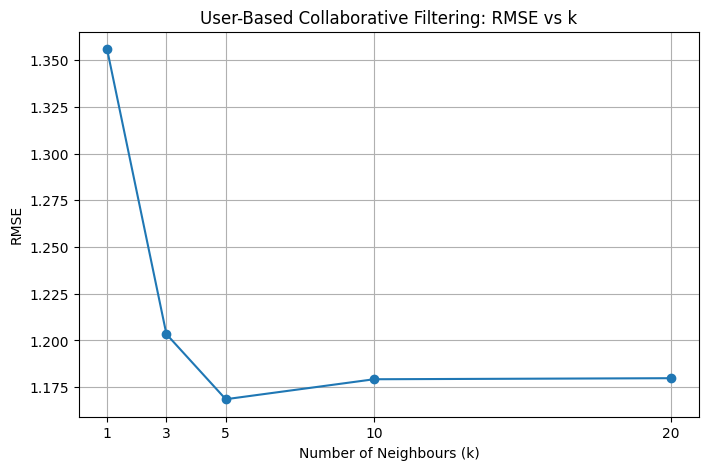

    k   RMSE
0   1  1.356
1   3  1.203
2   5  1.169
3  10  1.179
4  20  1.180


In [16]:
k_values = [1, 3, 5, 10, 20]
rmse_values = []

for k in k_values:
    predictions = [
        predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=k)
        for u, m in test_pairs
    ]

    rmse_values.append(rmse(predictions, true))

plt.figure(figsize=(8, 5))
plt.plot(k_values, rmse_values, marker="o")
plt.xlabel("Number of Neighbours (k)")
plt.ylabel("RMSE")
plt.title("User-Based Collaborative Filtering: RMSE vs k")
plt.xticks(k_values)
plt.grid(True)
plt.show()

print(pd.DataFrame({
    "k": k_values,
    "RMSE": np.round(rmse_values, 3)
}))

In [17]:
precision_values = []

for u in Rb.index:
    heldout_high = {
        m for uu, m in test_pairs
        if uu == u and Rb.loc[u, m] >= 4
    }

    if not heldout_high:
        continue

    unseen = Rb_train.loc[u][Rb_train.loc[u].isna()].index

    scores = {
        m: predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=5)
        for m in unseen
    }

    top3 = sorted(
        scores,
        key=scores.get,
        reverse=True
    )[:3]

    precision_values.append(
        len(set(top3) & heldout_high) / 3
    )

print("Number of evaluated users:", len(precision_values))
print("Precision@3:", round(np.mean(precision_values), 3))

Number of evaluated users: 31
Precision@3: 0.204


### Deliberate error 3: data leakage
The cell below computes the user similarities and means from the **full** matrix (including the hidden test ratings), then "predicts" them. Run it, compare with the honest RMSE above, and explain the gap. Would this error be visible if you only looked at the final number?

In [18]:
means_leak, sim_leak = build_user_cf(Rb)                       # WRONG: sees the test ratings
p_leak = [predict_user_cf(Rb_train, means_leak, sim_leak, u, m, k=5) for u, m in test_pairs]
print('leaky RMSE :', round(rmse(p_leak, true), 3))
print('honest RMSE:', round(rmse(p_cf, true), 3))


leaky RMSE : 0.621
honest RMSE: 1.169


*Your answer (one or two lines):*

The incorrect model uses test data during training, causing data leakage and an artificially low RMSE of 0.621 instead of 1.169. The lower error is misleading because the model has indirectly used information it should not have seen.

## Part 5: Cold Start and a Simple Hybrid
- **New user** (no ratings): CF has nothing to compare. **New item** (no ratings): CF cannot score it. Content-based can handle a new *item* because it only needs the description.
- A **hybrid** blends both: $\hat r = \alpha\,\hat r_{CF}+(1-\alpha)\,\hat r_{CB}$.

In [19]:
# A brand-new film: we know its text, nobody has rated it
new_desc = 'cricket match stadium team new'
sims_new = pd.Series(cosine_similarity(tfidf_b.transform([new_desc]), Tb).ravel(), index=items.title)
print('New film is most similar to:', list(sims_new.sort_values(ascending=False).head(3).index))
print('Their genres:', [items.set_index('title').genre[t] for t in sims_new.sort_values(ascending=False).head(3).index])


New film is most similar to: ['Film15', 'Film03', 'Film24']
Their genres: ['sports', 'sports', 'sports']


### Student Practice 6
1. Compute hybrid RMSE for $\alpha \in \{0, 0.25, 0.5, 0.75, 1\}$ using `p_cf` and `p_cb`. Which blend is best?
2. A user signs up and has rated **nothing**. Write a fallback recommender (hint: highest average rating among items with at least 3 ratings). State one weakness.
3. A brand-new film has **zero** ratings. Which of the three models (user-CF, item-CF, content-based) can still score it, and why?

In [20]:
# Write your answer here
alpha_values = [0, 0.25, 0.5, 0.75, 1]
hybrid_results = []

for alpha in alpha_values:
    p_hybrid = [
        alpha * cf + (1 - alpha) * cb
        for cf, cb in zip(p_cf, p_cb)
    ]

    hybrid_results.append(rmse(p_hybrid, true))

print(pd.DataFrame({
    "Alpha": alpha_values,
    "RMSE": np.round(hybrid_results, 3)
}))

   Alpha   RMSE
0   0.00  1.148
1   0.25  1.103
2   0.50  1.091
3   0.75  1.114
4   1.00  1.169


In [21]:
def recommend_new_user(R, n=3):
    rating_counts = R.notna().sum()
    average_ratings = R.mean()

    eligible = average_ratings[rating_counts >= 3]

    return eligible.sort_values(ascending=False).head(n)

print(recommend_new_user(R))

title
Curry Nights     4.333
Cricket Fever    4.000
Match Point      3.667
dtype: float64


Content-based filtering can recommend a new movie using its description, even if it has no ratings. Collaborative filtering needs user ratings or interaction history, so it requires a fallback method for new movies.

## Part 6: Mini Project (End-to-End Pipeline)
Before the project, one warm-up that you will repeat on your own data.

### Student Practice 7: the by-hand check
AI tools can write a recommender in minutes. What they cannot do is make *you* understand it. In your project you must reproduce **one prediction by hand** and show that your code gives the same number. Practise here:

`Esha -> Match Point` was predicted from her two positive-similarity neighbours, Bala (similarity 0.14) and Farid (0.07). Using only the ratings table and those two similarities, compute the prediction on paper with the user-based formula from Part 3, then compare with the code. Why is there a small difference?

In [22]:
# Write your answer here
prediction_manual = 4 + (
    0.14 * (5 - 3.4) +
    0.07 * (2 - 3.75)
) / (0.14 + 0.07)

prediction_code = predict_user_cf(
    R, means, sim_u, "Esha", "Match Point"
)

print("Manual prediction:", round(prediction_manual, 3))
print("Code prediction:", round(prediction_code, 3))

Manual prediction: 4.483
Code prediction: 4.54


# Mini Project: Build, Evaluate, Explain
Pick **one topic** from the handout `Week10_Recsys_Project_Menu.docx` (or propose your own with approval; it needs real user-item interaction data). Work in a pair. You have **one week**.

**AI tools are allowed and expected.** The point of the project is not typing code; it is that you understand every stage of a recommender pipeline and can defend it in an interview. So the project has two parts.

**Part A: the pipeline** (each a titled section of your notebook)
1. Problem and users
2. Data (source, licence, size, cleaning, sparsity)
3. EDA (distribution, long tail, two plots or more)
4. Baselines (global mean, user mean, most popular)
5. Content-based model
6. Collaborative model (mean-centred or confidence-weighted)
7. Matrix factorization (simple SVD) compared with your neighbourhood CF
8. Honest evaluation (split first, time-based if you have timestamps; RMSE, precision@k, NDCG@k)
9. Cold start or hybrid
10. Demo: `recommend(user_or_item, n)` printing readable results

**Part B: the understanding pack** (what shows it is yours)
- A by-hand check (as in Practice 7) on your own data
- A decision log (at least 5 decisions, each with the evidence)
- A bug log (at least 2 real problems you found and fixed) and a *deliberate-leak experiment*: reproduce leakage on purpose and report how much it inflates your metric
- 3 break-it tests (a new user, a new item, a user with one rating)
- An AI-use log: what you asked AI to do, what you checked, and one thing it got wrong
- A 5-minute walkthrough where each partner explains a different stage

Start from `Week10_Project_Starter_Template.ipynb`. Submit under `labs/week10_recsys/<team_name>/` on GitHub. Details, the one-week plan and the CV guide are in the handout.

## Part 7: Reflection (2 to 3 lines each)
1. When would you choose content-based over collaborative filtering, and vice versa?
2. Why do we mean-centre ratings? Use your Deliberate error 2 result.
3. What is the *filter bubble* problem, and which of the two methods makes it worse?
4. Your honest RMSE beat the global-mean baseline by how much? Is that enough to ship? What would you measure online (clicks, watch time) that RMSE cannot show?
5. Name one real product that uses a hybrid, and what each half contributes.
6. **Capstone link (Milestone, Week 10):** could a recommender be part of your capstone? If yes, sketch the user, the item, and the metric. If no, justify.

*Submit this notebook to GitHub under `labs/week10_recsys/`.*

### 1. When would you choose content-based over collaborative filtering, and vice versa?

I would choose content-based filtering when item descriptions are available, especially for new items. Collaborative filtering is better when many users have rated items because it learns preferences from their rating patterns.

### 2. Why do we mean-centre ratings? Use your Deliberate Error 2 result.

Mean-centring removes differences in users' average rating behaviour and identifies which items they like more or less than average. Treating missing ratings as zero in the raw matrix incorrectly affects similarity calculations.

### 3. What is the filter bubble problem, and which method makes it worse?

A filter bubble occurs when users repeatedly receive similar recommendations and miss discovering new content. Content-based filtering can worsen this problem because it recommends items similar to those users already like.

### 4. Your honest RMSE beat the global-mean baseline by how much? Is that enough to ship? What would you measure online?

The global-mean RMSE was 1.354, while user-based collaborative filtering achieved 1.169, an improvement of **0.185**. This alone is not enough to deploy the system; I would also measure click-through rate, watch time, and user satisfaction.

### 5. Name one real product that uses a hybrid, and what each half contributes.

Netflix is an example of a recommendation product that uses multiple signals. Content information identifies similar movies, while users' viewing behaviour helps predict their interests and personalise recommendations.

### 6. Could a recommender be part of your capstone? If yes, sketch the user, the item, and the metric.

Yes, I could build a recommendation system for an educational platform. The user would be a student, the items would be courses or tutorials, and the system could be evaluated using Precision@K and Recall@K.